In [ ]:
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt

SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4: {SID4} | SEED: {SEED} | SLICE: {SLICE} | HP_ID: {HP_ID} | CLS_A: {CLS_A} | CLS_B: {CLS_B}")


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

SID4: 2733 | SEED: 2733 | SLICE: 733 | HP_ID: 3 | CLS_A: 3 | CLS_B: 7
Device: cuda


In [ ]:
#  Part A: Dataset Loading  10% Labeled Subset
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform_train = T.Compose([
    T.RandomResizedCrop(96, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean, std)
])

transform_test = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std)
])

data_dir = './data'

# Load full labeled train split (5000 images) and test split (8000 images)
train_labeled_full = torchvision.datasets.STL10(data_dir, split='train', download=True, transform=transform_train)
test_set = torchvision.datasets.STL10(data_dir, split='test', download=True, transform=transform_test)

# Extract 10% of the labeled train split using SEED for reproducible sampling
num_total_train = len(train_labeled_full)
subset_size = int(0.10 * num_total_train) # 500 images

indices = list(range(num_total_train))
rng = np.random.default_rng(SEED)
rng.shuffle(indices)
subset_indices = indices[:subset_size]

train_10percent = Subset(train_labeled_full, subset_indices)

train_loader_10p = DataLoader(train_10percent, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print(f"Total labeled train size: {num_total_train}")
print(f"10% Labeled subset size (Part A): {len(train_10percent)}")
print(f"Test size: {len(test_set)}")

100%|██████████| 2.64G/2.64G [02:56<00:00, 14.9MB/s]


Total labeled train size: 5000
10% Labeled subset size (Part A): 500
Test size: 8000


In [ ]:
# --- Part A: Supervised Training with 10% Labeled Data ---
model_supervised = torchvision.models.resnet18(weights=None)
model_supervised.fc = nn.Linear(model_supervised.fc.in_features, 10)
model_supervised = model_supervised.to(device)

optimizer_sup = torch.optim.Adam(model_supervised.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_sup = nn.CrossEntropyLoss()

epochs_sup = 12

print("Starting Part A: Supervised Training...")
for epoch in range(1, epochs_sup + 1):
    model_supervised.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader_10p:
        x, y = x.to(device), y.to(device)

        optimizer_sup.zero_grad(set_to_none=True)
        outputs = model_supervised(x)
        loss = criterion_sup(outputs, y)

        loss.backward()
        optimizer_sup.step()

        running_loss += loss.item() * x.size(0)
        _, preds = outputs.max(1)
        total += y.size(0)
        correct += preds.eq(y).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Supervised Epoch [{epoch}/{epochs_sup}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")

# Evaluate Supervised model on Test Set
model_supervised.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = model_supervised(x)
        _, preds = outputs.max(1)
        test_total += y.size(0)
        test_correct += preds.eq(y).sum().item()

test_acc_sup = test_correct / test_total
print(f"\nPart A Complete — Supervised Test Accuracy: {test_acc_sup * 100:.2f}%")

Starting Part A: Supervised Training...
Supervised Epoch [1/12] | Loss: 2.1612 | Train Acc: 0.2360
Supervised Epoch [2/12] | Loss: 1.7183 | Train Acc: 0.3460
Supervised Epoch [3/12] | Loss: 1.4680 | Train Acc: 0.4520
Supervised Epoch [4/12] | Loss: 1.3011 | Train Acc: 0.5380
Supervised Epoch [5/12] | Loss: 1.0497 | Train Acc: 0.6500
Supervised Epoch [6/12] | Loss: 0.9978 | Train Acc: 0.6500
Supervised Epoch [7/12] | Loss: 0.8843 | Train Acc: 0.6660
Supervised Epoch [8/12] | Loss: 0.7994 | Train Acc: 0.7100
Supervised Epoch [9/12] | Loss: 0.6739 | Train Acc: 0.7780
Supervised Epoch [10/12] | Loss: 0.6423 | Train Acc: 0.7980
Supervised Epoch [11/12] | Loss: 0.6307 | Train Acc: 0.7880
Supervised Epoch [12/12] | Loss: 0.4915 | Train Acc: 0.8320

Part A Complete — Supervised Test Accuracy: 38.34%


In [ ]:
# Part B Step 1. Rotation SSL Dataset Setup
transform_rot = T.Compose([
    T.RandomResizedCrop(96, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean, std)
])

# Load all unlabeled images from STL-10 (100,000 images)
unlabeled_set = torchvision.datasets.STL10(data_dir, split='unlabeled', download=False, transform=transform_rot)

class RotationDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, _ = self.base_dataset[idx]
        rot_label = random.randint(0, 3) # 0: 0°, 1: 90°, 2: 180°, 3: 270°

        if rot_label == 0:
            img_rotated = img
        elif rot_label == 1:
            img_rotated = torch.rot90(img, 1, [1, 2])
        elif rot_label == 2:
            img_rotated = torch.rot90(img, 2, [1, 2])
        else:
            img_rotated = torch.rot90(img, 3, [1, 2])

        return img_rotated, torch.tensor(rot_label, dtype=torch.long)

rot_dataset = RotationDataset(unlabeled_set)
rot_loader = DataLoader(rot_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)

print(f"Rotation SSL dataset size (all unlabeled images): {len(rot_dataset)}")

Rotation SSL dataset size (all unlabeled images): 100000


In [ ]:
#  Part B Step 2: Train Rotation Encoder
encoder_rot = torchvision.models.resnet18(weights=None)
encoder_rot.fc = nn.Identity()
encoder_rot = encoder_rot.to(device)

rot_head = nn.Linear(512, 4).to(device)

optimizer_rot = torch.optim.Adam(
    list(encoder_rot.parameters()) + list(rot_head.parameters()),
    lr=3e-4,
    weight_decay=1e-4
)
criterion_rot = nn.CrossEntropyLoss()

epochs_rot = 12

print("Starting Part B: Rotation Self-Supervised Pretraining...")
for epoch in range(1, epochs_rot + 1):
    encoder_rot.train()
    rot_head.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for step, (x, r) in enumerate(rot_loader):
        x, r = x.to(device), r.to(device)

        optimizer_rot.zero_grad(set_to_none=True)
        features = encoder_rot(x)
        logits = rot_head(features)
        loss = criterion_rot(logits, r)

        loss.backward()
        optimizer_rot.step()

        running_loss += loss.item() * x.size(0)
        _, preds = logits.max(1)
        total += r.size(0)
        correct += preds.eq(r).sum().item()

        if step % 250 == 0:
            print(f"  Epoch [{epoch}/{epochs_rot}] Step [{step}/{len(rot_loader)}] Loss: {loss.item():.4f}")

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"[Rotation SSL Epoch {epoch}] Mean Loss: {epoch_loss:.4f} | Rotation Acc: {epoch_acc:.4f}")

print("Rotation Self-Supervised Pretraining Complete.")

Starting Part B: Rotation Self-Supervised Pretraining...
  Epoch [1/12] Step [0/782] Loss: 1.4581
  Epoch [1/12] Step [250/782] Loss: 1.0410
  Epoch [1/12] Step [500/782] Loss: 0.9650
  Epoch [1/12] Step [750/782] Loss: 0.9040
[Rotation SSL Epoch 1] Mean Loss: 0.9843 | Rotation Acc: 0.5861
  Epoch [2/12] Step [0/782] Loss: 0.9766
  Epoch [2/12] Step [250/782] Loss: 0.7665
  Epoch [2/12] Step [500/782] Loss: 0.8614
  Epoch [2/12] Step [750/782] Loss: 0.6832
[Rotation SSL Epoch 2] Mean Loss: 0.7939 | Rotation Acc: 0.6796
  Epoch [3/12] Step [0/782] Loss: 0.7034
  Epoch [3/12] Step [250/782] Loss: 0.7757
  Epoch [3/12] Step [500/782] Loss: 0.6924
  Epoch [3/12] Step [750/782] Loss: 0.5201
[Rotation SSL Epoch 3] Mean Loss: 0.7106 | Rotation Acc: 0.7177
  Epoch [4/12] Step [0/782] Loss: 0.6942
  Epoch [4/12] Step [250/782] Loss: 0.5889
  Epoch [4/12] Step [500/782] Loss: 0.6447
  Epoch [4/12] Step [750/782] Loss: 0.6703
[Rotation SSL Epoch 4] Mean Loss: 0.6597 | Rotation Acc: 0.7388
  Epoch

In [ ]:
# Part B Step 3: Linear Evaluation on Frozen Rotation Encoder

# Freeze the encoder parameters completely
for param in encoder_rot.parameters():
    param.requires_grad = False
encoder_rot.eval()

# Define a linear classifier for the 10 classes of STL-10
linear_classifier_rot = nn.Linear(512, 10).to(device)

optimizer_lin = torch.optim.Adam(linear_classifier_rot.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_lin = nn.CrossEntropyLoss()

epochs_lin = 15

print("Starting Part B: Linear Evaluation (Frozen Rotation Encoder)...")
for epoch in range(1, epochs_lin + 1):
    linear_classifier_rot.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader_10p:
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            features = encoder_rot(x) # Extract frozen features [B, 512]

        optimizer_lin.zero_grad(set_to_none=True)
        outputs = linear_classifier_rot(features)
        loss = criterion_lin(outputs, y)

        loss.backward()
        optimizer_lin.step()

        running_loss += loss.item() * x.size(0)
        _, preds = outputs.max(1)
        total += y.size(0)
        correct += preds.eq(y).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Linear Eval Epoch [{epoch}/{epochs_lin}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")

# Evaluate Rotation SSL model on Test Set
linear_classifier_rot.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        features = encoder_rot(x)
        outputs = linear_classifier_rot(features)
        _, preds = outputs.max(1)
        test_total += y.size(0)
        test_correct += preds.eq(y).sum().item()

test_acc_rot = test_correct / test_total
print(f"\nPart B  — Rotation SSL Test Accuracy: {test_acc_rot * 100:.2f}%")

Starting Part B: Linear Evaluation (Frozen Rotation Encoder)...
Linear Eval Epoch [1/15] | Loss: 2.2708 | Train Acc: 0.1300
Linear Eval Epoch [2/15] | Loss: 2.1109 | Train Acc: 0.1640
Linear Eval Epoch [3/15] | Loss: 2.0047 | Train Acc: 0.3000
Linear Eval Epoch [4/15] | Loss: 1.9222 | Train Acc: 0.3160
Linear Eval Epoch [5/15] | Loss: 1.8502 | Train Acc: 0.3540
Linear Eval Epoch [6/15] | Loss: 1.8182 | Train Acc: 0.3740
Linear Eval Epoch [7/15] | Loss: 1.7759 | Train Acc: 0.3760
Linear Eval Epoch [8/15] | Loss: 1.7387 | Train Acc: 0.3960
Linear Eval Epoch [9/15] | Loss: 1.7242 | Train Acc: 0.4140
Linear Eval Epoch [10/15] | Loss: 1.6989 | Train Acc: 0.4220
Linear Eval Epoch [11/15] | Loss: 1.6671 | Train Acc: 0.4240
Linear Eval Epoch [12/15] | Loss: 1.6446 | Train Acc: 0.4300
Linear Eval Epoch [13/15] | Loss: 1.6387 | Train Acc: 0.4420
Linear Eval Epoch [14/15] | Loss: 1.6105 | Train Acc: 0.4520
Linear Eval Epoch [15/15] | Loss: 1.5935 | Train Acc: 0.4440

Part B  — Rotation SSL Test A

In [ ]:
#  Part C Step 1: SimCLR Dataset  Augmentations Setup
simclr_transform = T.Compose([
    T.RandomResizedCrop(96, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    T.RandomGrayscale(p=0.2),
    T.ToTensor(),
    T.Normalize(mean, std)
])

# Use a subset of unlabeled data (20,000 images for efficiency)
unlabeled_full = torchvision.datasets.STL10(data_dir, split='unlabeled', download=False, transform=None)
num_unlabeled = len(unlabeled_full)

unlabeled_indices = list(range(num_unlabeled))
rng_sim = np.random.default_rng(SEED)
rng_sim.shuffle(unlabeled_indices)
simclr_indices = unlabeled_indices[:20000] # Takes 20,000 images

class SimCLRDataset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, _ = self.base_dataset[real_idx] # PIL image

        # Create two augmented views per image
        view1 = self.transform(img)
        view2 = self.transform(img)
        return view1, view2

simclr_dataset = SimCLRDataset(unlabeled_full, simclr_indices, simclr_transform)
simclr_loader = DataLoader(simclr_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)

print(f"SimCLR dataset loaded with {len(simclr_dataset)} images.")

SimCLR dataset loaded with 20000 images.


In [ ]:
# Part C Step 2: SimCLR Model, Loss,  Pretraining
encoder_sim = torchvision.models.resnet18(weights=None)
encoder_sim.fc = nn.Identity() # Output 512-d features

projection_head = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Linear(256, 128)
).to(device)

encoder_sim = encoder_sim.to(device)

def nt_xent_loss(z1, z2, tau=0.2):

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    B = z1.size(0)

    z = torch.cat([z1, z2], dim=0) # [2B, D]
    sim = torch.mm(z, z.t()) / tau   # [2B, 2B]

    # Mask out self-similarities
    mask = torch.eye(2 * B, dtype=torch.bool, device=z.device)
    sim.masked_fill_(mask, -9150.0)

    # Positive pairs are at indices (i, i+B) and (i+B, i)
    pos = torch.cat([torch.diag(sim, B), torch.diag(sim, -B)], dim=0)

    # Logsumexp denominator over all negatives/positives
    denominator = torch.logsumexp(sim, dim=1)
    loss = (-pos + denominator).mean()
    return loss

optimizer_sim = torch.optim.Adam(
    list(encoder_sim.parameters()) + list(projection_head.parameters()),
    lr=3e-4,
    weight_decay=1e-4
)

epochs_sim = 12

print("Starting Part C: SimCLR Contrastive Pretraining...")
for epoch in range(1, epochs_sim + 1):
    encoder_sim.train()
    projection_head.train()
    running_loss = 0.0

    for step, (x1, x2) in enumerate(simclr_loader):
        x1, x2 = x1.to(device), x2.to(device)

        optimizer_sim.zero_grad(set_to_none=True)

        h1 = encoder_sim(x1)
        h2 = encoder_sim(x2)
        z1 = projection_head(h1)
        z2 = projection_head(h2)

        loss = nt_xent_loss(z1, z2, tau=0.2)
        loss.backward()
        optimizer_sim.step()

        running_loss += loss.item() * x1.size(0)

        if step % 50 == 0:
            print(f"  Epoch [{epoch}/{epochs_sim}] Step [{step}/{len(simclr_loader)}] Loss: {loss.item():.4f}")

    epoch_loss = running_loss / len(simclr_dataset)
    print(f"[SimCLR Epoch {epoch}] Mean Loss: {epoch_loss:.4f}")

print("SimCLR Contrastive Pretraining Completed.")

Starting Part C: SimCLR Contrastive Pretraining...
  Epoch [1/12] Step [0/156] Loss: 5.4566
  Epoch [1/12] Step [50/156] Loss: 3.3881
  Epoch [1/12] Step [100/156] Loss: 2.8700
  Epoch [1/12] Step [150/156] Loss: 2.5481
[SimCLR Epoch 1] Mean Loss: 3.3230
  Epoch [2/12] Step [0/156] Loss: 2.7363
  Epoch [2/12] Step [50/156] Loss: 2.4741
  Epoch [2/12] Step [100/156] Loss: 2.3410
  Epoch [2/12] Step [150/156] Loss: 2.2755
[SimCLR Epoch 2] Mean Loss: 2.4160
  Epoch [3/12] Step [0/156] Loss: 2.3175
  Epoch [3/12] Step [50/156] Loss: 2.2055
  Epoch [3/12] Step [100/156] Loss: 2.2842
  Epoch [3/12] Step [150/156] Loss: 2.1365
[SimCLR Epoch 3] Mean Loss: 2.2172
  Epoch [4/12] Step [0/156] Loss: 2.1424
  Epoch [4/12] Step [50/156] Loss: 2.1458
  Epoch [4/12] Step [100/156] Loss: 2.0756
  Epoch [4/12] Step [150/156] Loss: 2.0423
[SimCLR Epoch 4] Mean Loss: 2.1001
  Epoch [5/12] Step [0/156] Loss: 2.2111
  Epoch [5/12] Step [50/156] Loss: 1.9713
  Epoch [5/12] Step [100/156] Loss: 2.0557
  Epoch

In [ ]:
#  Part C Step 3: Linear Evaluation on Frozen SimCLR Encoder

# Freeze the SimCLR encoder completely
for param in encoder_sim.parameters():
    param.requires_grad = False
encoder_sim.eval()

linear_classifier_sim = nn.Linear(512, 10).to(device)
optimizer_lin_sim = torch.optim.Adam(linear_classifier_sim.parameters(), lr=1e-3, weight_decay=1e-4)
criterion_lin_sim = nn.CrossEntropyLoss()

epochs_lin_sim = 15 # Approximately 15–20 epochs

print("Starting Part C: Linear Evaluation (Frozen SimCLR Encoder)...")
for epoch in range(1, epochs_lin_sim + 1):
    linear_classifier_sim.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader_10p:
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            features = encoder_sim(x) # Extract frozen features [B, 512]

        optimizer_lin_sim.zero_grad(set_to_none=True)
        outputs = linear_classifier_sim(features)
        loss = criterion_lin_sim(outputs, y)

        loss.backward()
        optimizer_lin_sim.step()

        running_loss += loss.item() * x.size(0)
        _, preds = outputs.max(1)
        total += y.size(0)
        correct += preds.eq(y).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"SimCLR Linear Eval Epoch [{epoch}/{epochs_lin_sim}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")

# Evaluate SimCLR model on Test Set
linear_classifier_sim.eval()
test_correct = 0
test_total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        features = encoder_sim(x)
        outputs = linear_classifier_sim(features)
        _, preds = outputs.max(1)
        test_total += y.size(0)
        test_correct += preds.eq(y).sum().item()

test_acc_sim = test_correct / test_total
print(f"\nPart C Complete — SimCLR Test Accuracy: {test_acc_sim * 100:.2f}%")

Starting Part C: Linear Evaluation (Frozen SimCLR Encoder)...
SimCLR Linear Eval Epoch [1/15] | Loss: 2.2473 | Train Acc: 0.2020
SimCLR Linear Eval Epoch [2/15] | Loss: 1.6875 | Train Acc: 0.3720
SimCLR Linear Eval Epoch [3/15] | Loss: 1.4379 | Train Acc: 0.4660
SimCLR Linear Eval Epoch [4/15] | Loss: 1.3338 | Train Acc: 0.5200
SimCLR Linear Eval Epoch [5/15] | Loss: 1.2688 | Train Acc: 0.5360
SimCLR Linear Eval Epoch [6/15] | Loss: 1.2153 | Train Acc: 0.5460
SimCLR Linear Eval Epoch [7/15] | Loss: 1.1813 | Train Acc: 0.5700
SimCLR Linear Eval Epoch [8/15] | Loss: 1.1583 | Train Acc: 0.5860
SimCLR Linear Eval Epoch [9/15] | Loss: 1.1366 | Train Acc: 0.5940
SimCLR Linear Eval Epoch [10/15] | Loss: 1.1025 | Train Acc: 0.6040
SimCLR Linear Eval Epoch [11/15] | Loss: 1.0785 | Train Acc: 0.6160
SimCLR Linear Eval Epoch [12/15] | Loss: 1.0758 | Train Acc: 0.6160
SimCLR Linear Eval Epoch [13/15] | Loss: 1.0527 | Train Acc: 0.6220
SimCLR Linear Eval Epoch [14/15] | Loss: 1.0370 | Train Acc: 0.

Extracting test embeddings for all models...

Nearest Neighbors for: Part A: Supervised (10% Labels)


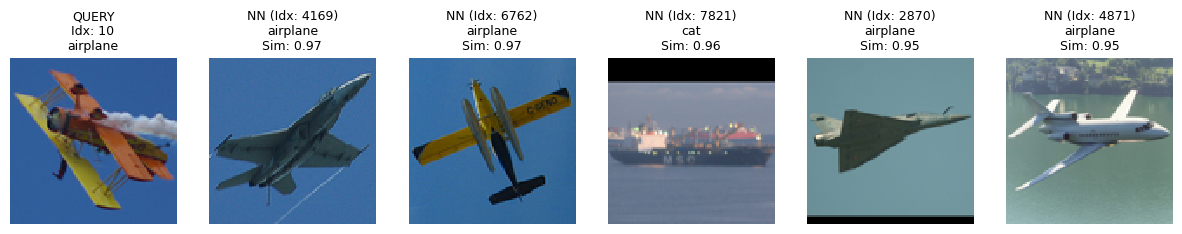

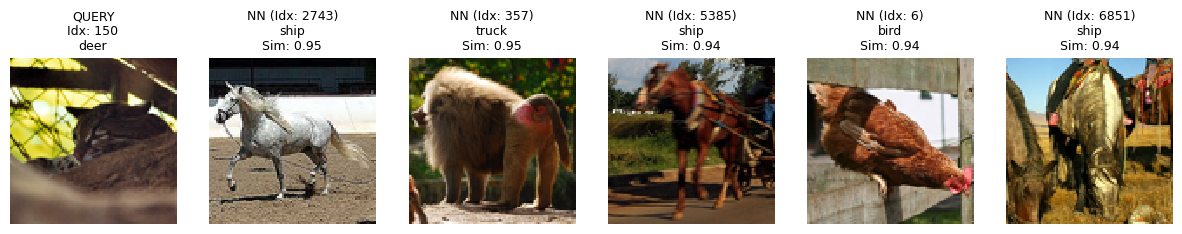

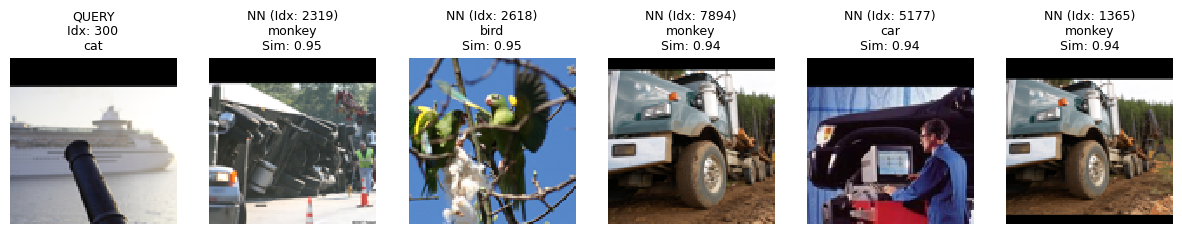


Nearest Neighbors for: Part B: Rotation SSL


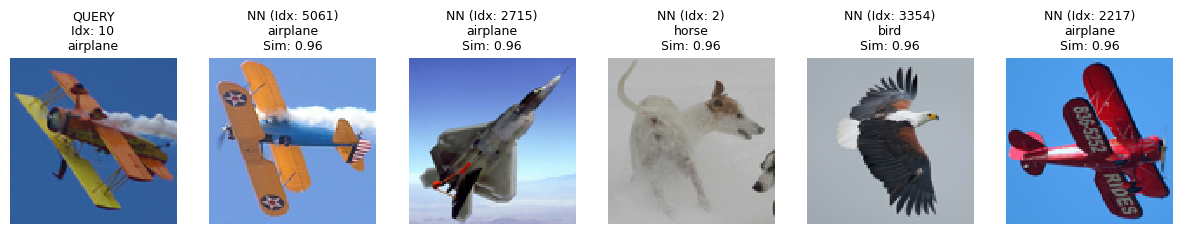

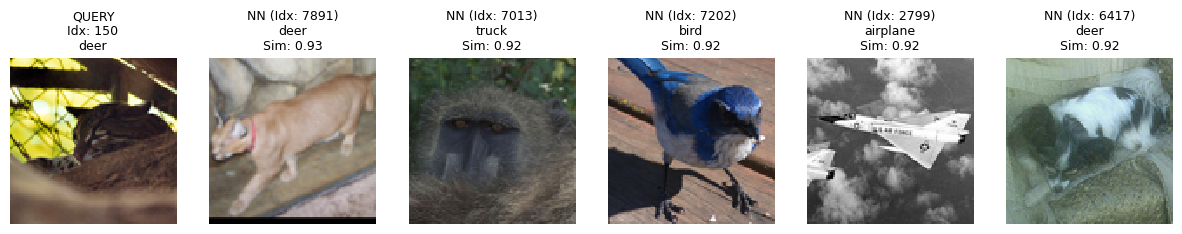

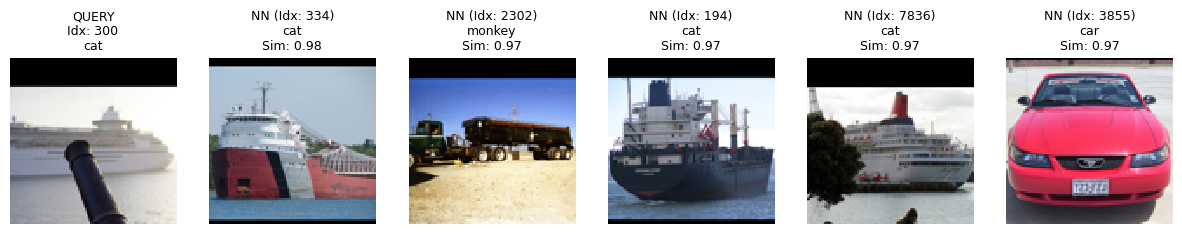


Nearest Neighbors for: Part C: SimCLR Contrastive


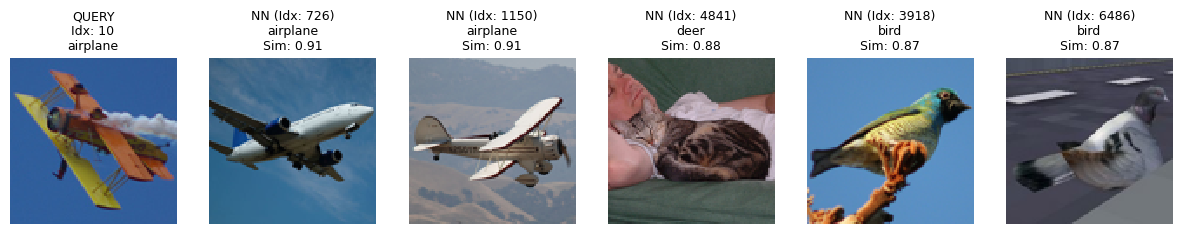

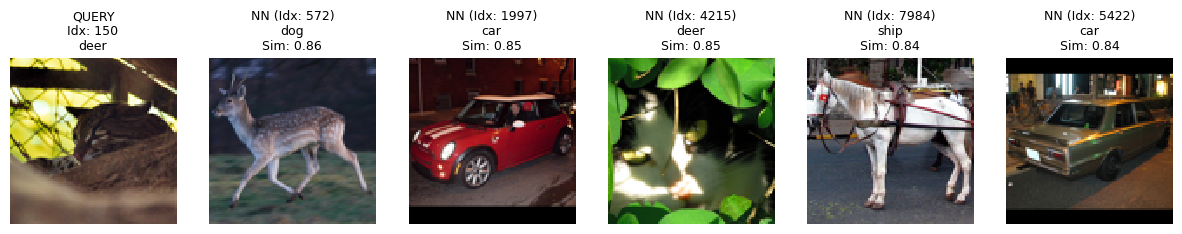

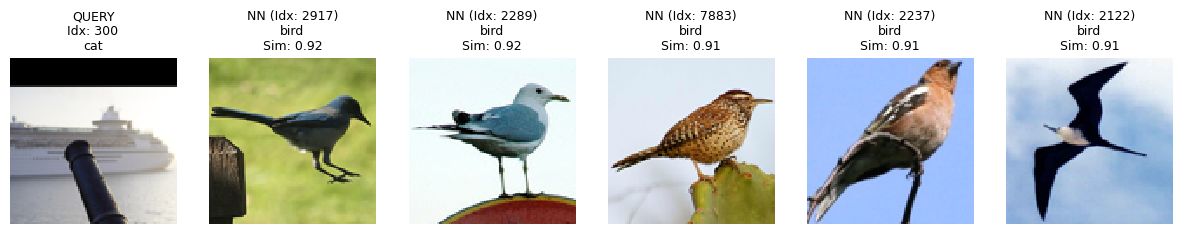

In [ ]:
# Part D: Nearest Neighbor Visualization and Retrieval
@torch.no_grad()
def get_all_embeddings(encoder, loader):
    encoder.eval()
    embs = []
    for x, _ in loader:
        x = x.to(device)
        z = encoder(x)
        z = F.normalize(z, dim=1)
        embs.append(z.cpu())
    return torch.cat(embs, dim=0) # [N, 512]

print("Extracting test embeddings for all models...")

# Reuse model_supervised directly as our supervised encoder by setting its fc layer to Identity
model_supervised.fc = nn.Identity()
supervised_encoder = model_supervised.to(device)

emb_sup = get_all_embeddings(supervised_encoder, test_loader)
emb_rot = get_all_embeddings(encoder_rot, test_loader)
emb_sim = get_all_embeddings(encoder_sim, test_loader)

def show_pil_row(pil_images, titles=None, figsize=(14, 3)):
    fig, axes = plt.subplots(1, len(pil_images), figsize=figsize)
    if len(pil_images) == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        ax.imshow(pil_images[i], interpolation="nearest")
        ax.axis("off")
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.show()

# Use raw unnormalized test dataset for clear visualization
test_raw = torchvision.datasets.STL10(data_dir, split='test', download=False, transform=None)
classes = ['airplane', 'bird', 'car', 'deer', 'dog', 'horse', 'ship', 'truck', 'cat', 'monkey'] # STL-10 classes

# Select at least 3 query images (using same indices across all models)
query_indices = [10, 150, 300]

def retrieve_and_plot_neighbors(embeddings, model_name):
    print(f"\n{'='*50}\nNearest Neighbors for: {model_name}\n{'='*50}")
    E = embeddings

    for qi in query_indices:
        q_img, q_y = test_raw[qi]
        q_emb = E[qi]

        sims = torch.mv(E, q_emb) # Cosine similarity since normalized
        topk = torch.topk(sims, k=6).indices.tolist()
        topk = [j for j in topk if j != qi][:5] # Remove self, take top 5

        disp_imgs = [q_img.resize((96, 96), resample=0)]
        disp_titles = [f"QUERY\nIdx: {qi}\n{classes[q_y]}"]

        for j in topk:
            img_j, y_j = test_raw[j]
            disp_imgs.append(img_j.resize((96, 96), resample=0))
            disp_titles.append(f"NN (Idx: {j})\n{classes[y_j]}\nSim: {sims[j]:.2f}")

        show_pil_row(disp_imgs, titles=disp_titles, figsize=(15, 3))

retrieve_and_plot_neighbors(emb_sup, "Part A: Supervised (10% Labels)")
retrieve_and_plot_neighbors(emb_rot, "Part B: Rotation SSL")
retrieve_and_plot_neighbors(emb_sim, "Part C: SimCLR Contrastive")

## Comparison and Discussion

SimCLR performed best, achieving 47.23% test accuracy. The supervised model achieved 38.34%, while the rotation-based model achieved 37.66%. SimCLR likely performed better because its contrastive objective encourages different augmented views of the same image to have similar representations while separating different images.
The supervised model was limited by having only 500 labeled images. Rotation SSL learned features useful for predicting image orientation, but those features were not as closely related to the STL-10 object classes. SimCLR used many unlabeled images and data augmentations, which helped it learn more general visual representations.
The nearest-neighbor visualizations should show more semantically similar neighbors for SimCLR. The supervised model may retrieve some class-related images but is limited by the small labeled dataset. The rotation encoder may retrieve images based more on shape, orientation, or low-level visual features than object category.